In [1]:
# import libraries

import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
#add shapefile
block_groups = gpd.read_file("data/tutorial02-data/nhgis_nyc_block_grp/nyc_block_grp_2022.shp")

<Axes: >

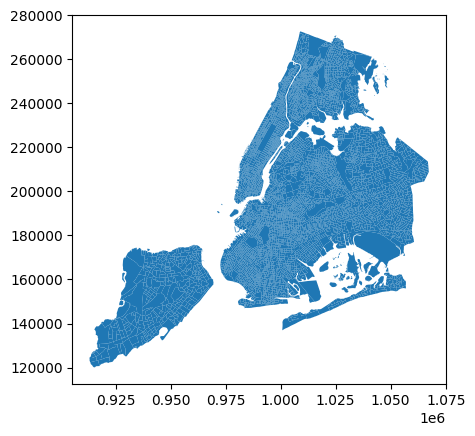

In [7]:
#map of NYC with the census block
block_groups.plot()

In [8]:
#explore the data
block_groups.head()

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,GEOID,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,ORIG_FID,geometry
0,G36000500001001,36,005,000100,1,360050001001,Block Group 1,G5030,S,1677210.0,0.0,+40.7911136,-073.8826858,5337.031119,1.677210e+06,202823,"POLYGON ((1015582.61 230043.615, 1016411.575 2..."
1,G36000500002001,36,005,000200,1,360050002001,Block Group 1,G5030,S,89013.0,0.0,+40.8139633,-073.8608664,1253.660382,8.901347e+04,208140,"POLYGON ((1023634.415 235638.799, 1023497.987 ..."
2,G36000500002002,36,005,000200,2,360050002002,Block Group 2,G5030,S,195476.0,0.0,+40.8113967,-073.8600538,3862.477414,1.954764e+05,208141,"POLYGON ((1023634.415 235638.799, 1023790.855 ..."
3,G36000500002003,36,005,000200,3,360050002003,Block Group 3,G5030,S,163616.0,0.0,+40.8082452,-073.8567226,2019.237229,1.636185e+05,202824,"POLYGON ((1024217.921 234636.372, 1024263.164 ..."
4,G36000500004001,36,005,000400,1,360050004001,Block Group 1,G5030,S,62874.0,0.0,+40.8139792,-073.8573467,1451.109087,6.287329e+04,208142,"POLYGON ((1024217.921 234636.372, 1024074.876 ..."


In [9]:
#count the amount of census and columns that represent these geometries
print(block_groups.shape, block_groups.crs)

(6593, 17) EPSG:2263


In [10]:
#examine the column types of the block groups
print(block_groups.dtypes)

GISJOIN            str
STATEFP            str
COUNTYFP           str
TRACTCE            str
BLKGRPCE           str
GEOID              str
NAMELSAD           str
MTFCC              str
FUNCSTAT           str
ALAND          float64
AWATER         float64
INTPTLAT           str
INTPTLON           str
Shape_Leng     float64
Shape_Area     float64
ORIG_FID         int64
geometry      geometry
dtype: object


In [13]:
#Examine metadata

housing = pd.read_csv(
    "data/tutorial02-data/nhgis_nyc_20225_blck_grp_housing/nhgis_nyc_20225_blck_grp_housing.csv",
    index_col=0,
    dtype={"TL_GEO_ID": str},
)
housing.head()

,GISJOIN,TL_GEO_ID,YEAR,STUSAB,REGIONA,DIVISIONA,STATE,STATEA,COUNTY,COUNTYA,...,AQSQE002,AQSQE003,AQUME001,AQUSE001,NAME_M,AQSQM001,AQSQM002,AQSQM003,AQUMM001,AQUSM001
286,G36000500001000,360050001000,2018-2022,NY,NaN,NaN,New York,36,Bronx County,5,...,0,0,NaN,NaN,"Block Group 0, Census Tract 1, Bronx County, N...",13,13,13,NaN,NaN
287,G36000500001001,360050001001,2018-2022,NY,NaN,NaN,New York,36,Bronx County,5,...,0,0,NaN,NaN,"Block Group 1, Census Tract 1, Bronx County, N...",13,13,13,NaN,NaN
288,G36000500002000,360050002000,2018-2022,NY,NaN,NaN,New York,36,Bronx County,5,...,0,0,NaN,NaN,"Block Group 0, Census Tract 2, Bronx County, N...",13,13,13,NaN,NaN
289,G36000500002001,360050002001,2018-2022,NY,NaN,NaN,New York,36,Bronx County,5,...,218,99,1604.0,2104.0,"Block Group 1, Census Tract 2, Bronx County, N...",106,82,79,874.0,1452.0
290,G36000500002002,360050002002,2018-2022,NY,NaN,NaN,New York,36,Bronx County,5,...,321,379,1470.0,1899.0,"Block Group 2, Census Tract 2, Bronx County, N...",256,112,245,341.0,642.0


In [14]:
print(block_groups["GEOID"].dtype)
print(housing["TL_GEO_ID"].dtype)

str
str


In [15]:
#Performing join

joined = block_groups.merge(
    housing.drop(columns="GISJOIN"),
    left_on="GEOID",
    right_on="TL_GEO_ID",
    how="left",
    validate="1:1",
)

In [16]:
print(joined.shape)
joined.head()

(6593, 42)


,GISJOIN,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,GEOID,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,AQSQE002,AQSQE003,AQUME001,AQUSE001,NAME_M,AQSQM001,AQSQM002,AQSQM003,AQUMM001,AQUSM001
0,G36000500001001,36,005,000100,1,360050001001,Block Group 1,G5030,S,1677210.0,...,0,0,NaN,NaN,"Block Group 1, Census Tract 1, Bronx County, N...",13,13,13,NaN,NaN
1,G36000500002001,36,005,000200,1,360050002001,Block Group 1,G5030,S,89013.0,...,218,99,1604.0,2104.0,"Block Group 1, Census Tract 2, Bronx County, N...",106,82,79,874.0,1452.0
2,G36000500002002,36,005,000200,2,360050002002,Block Group 2,G5030,S,195476.0,...,321,379,1470.0,1899.0,"Block Group 2, Census Tract 2, Bronx County, N...",256,112,245,341.0,642.0
3,G36000500002003,36,005,000200,3,360050002003,Block Group 3,G5030,S,163616.0,...,319,89,1815.0,2085.0,"Block Group 3, Census Tract 2, Bronx County, N...",109,100,59,138.0,389.0
4,G36000500004001,36,005,000400,1,360050004001,Block Group 1,G5030,S,62874.0,...,185,118,NaN,NaN,"Block Group 1, Census Tract 4, Bronx County, N...",157,120,150,NaN,NaN


In [17]:
#Save the joined data

joined.to_file("data/processed/nyc_block_grp_2022_joined.fgb")

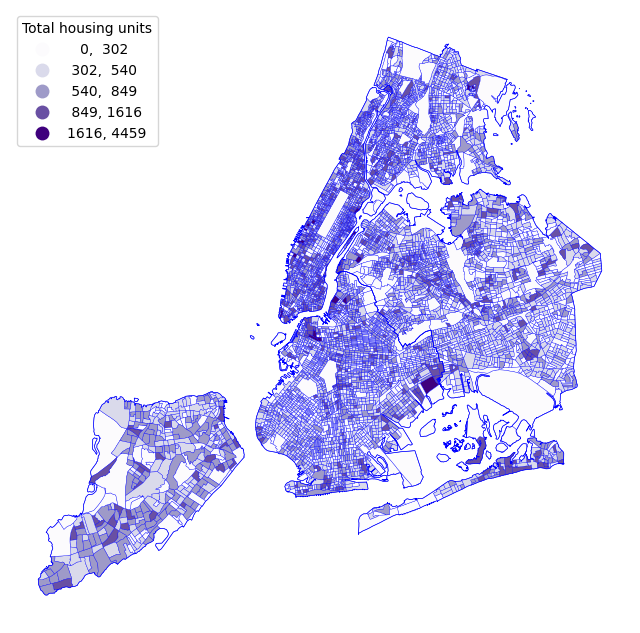

In [24]:
# we can dissolve by county to get an outline for each borough to plot beneath the block groups
ax = joined.dissolve("COUNTYFP").boundary.plot(
    edgecolor="#0000ff", linewidth=0.5, alpha=1, figsize=(8, 8)
)
joined.plot(
    ax=ax,
    column="AQSQE001",
    scheme="NaturalBreaks",
    k=5,
    cmap="Purples",
    edgecolor="#0000ff",
    linewidth=0.25,
    legend=True,
    legend_kwds={"title": "Total housing units", "fmt": "{:.0f}", "loc": "upper left"},
)
ax.set_axis_off()

In [26]:
# classification scheme determines how your data is grouped and which data values correspond to which colors

classes = mapclassify.NaturalBreaks(joined["AQSQE001"], k=5)
classes

NaturalBreaks

     Interval        Count
--------------------------
[   0.00,  307.00] |  1471
( 307.00,  547.00] |  2787
( 547.00,  859.00] |  1703
( 859.00, 1700.00] |   615
(1700.00, 4459.00] |    17

Text(0, 0.5, 'Number of census block groups')

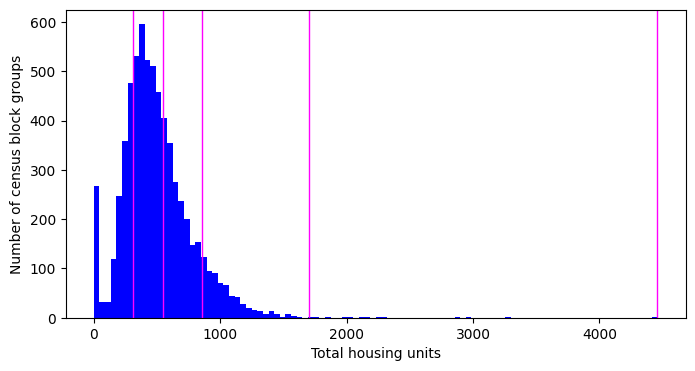

In [31]:
#histogram and add a vertical line at each class break

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(joined["AQSQE001"], bins=100, color="#0000ff")
for class_break in classes.bins:
    ax.axvline(class_break, color="#ff00ff", linewidth=1)
ax.set_xlabel("Total housing units")
ax.set_ylabel("Number of census block groups")

In [34]:
import rasterio
from matplotlib.colors import ListedColormap
from rasterio.windows import from_bounds

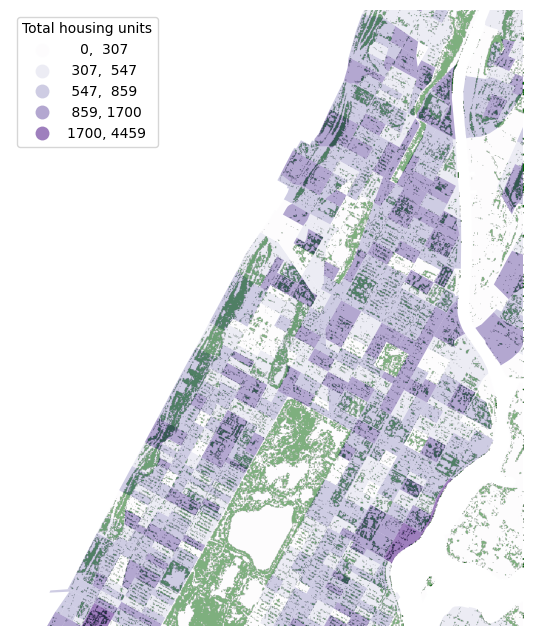

In [36]:
# the area to map, in the coordinates of EPSG:2263 (feet)
# we could alternately construct these values from the bounding box of a geometry or set of geometries, e.g. `block_groups.loc[0, "geometry"].bounds`
xmin, xmax, ymin, ymax = 985000, 1005000, 222000, 246000

with rasterio.open(
    "data/tutorial02-data/Land_Cover_2010/landcover_2010_nyc_3ft.img"
) as src:
    window = from_bounds(xmin, ymin, xmax, ymax, transform=src.transform)
    landcover = src.read(1, window=window, out_shape=(1200, 1000))

# hide every cell that is not tree canopy
canopy = np.ma.masked_where(landcover != 1, landcover)

fig, ax = plt.subplots(figsize=(8, 8))
# limit the raster image to the area of interest and color it dark green
ax.imshow(canopy, extent=(xmin, xmax, ymin, ymax), cmap=ListedColormap(["darkgreen"]))

# plot the block groups on top of the raster, using the class breaks you found above
# we can decorate the legend with keyword arguments, including a title, the format of the numbers, and the location of the legend (without the location, it will cover the map)
joined.plot(
    ax=ax,
    column="AQSQE001",
    scheme="UserDefined",
    classification_kwds={"bins": classes.bins},
    cmap="Purples",
    alpha=0.5,
    legend=True,
    legend_kwds={"title": "Total housing units", "fmt": "{:.0f}", "loc": "upper left"},
)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()

In [37]:
#  Calculate a new column, which works like the Field Calculator

joined["pct_owner"] = joined["AQSQE002"] / joined["AQSQE001"]
joined["pct_owner"].describe()

count    6368.000000
mean        0.357512
std         0.289200
min         0.000000
25%         0.100761
50%         0.307032
75%         0.578810
max         1.000000
Name: pct_owner, dtype: float64

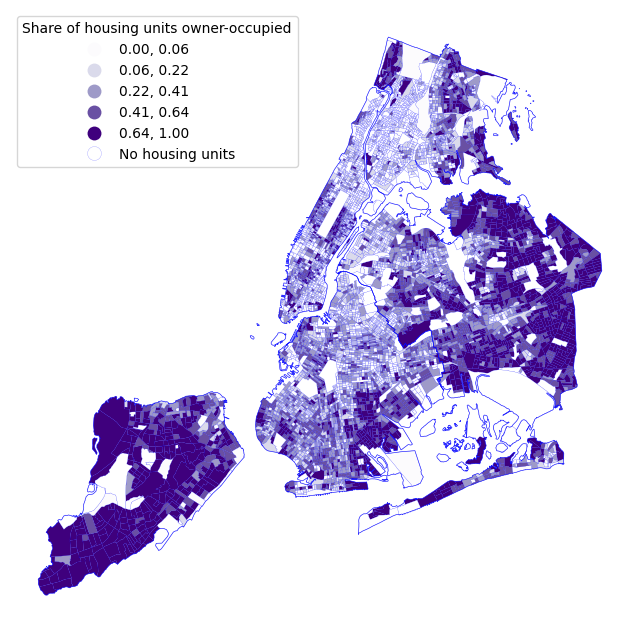

In [42]:
ax = joined.dissolve("COUNTYFP").boundary.plot(
    edgecolor="#0000ff", linewidth=0.5, alpha=0.75, figsize=(8, 8)
)
joined.plot(
    ax=ax,
    column="pct_owner",
    scheme="Quantiles",
    k=5,
    cmap="Purples",
    edgecolor="#0000ff",
    linewidth=0.1,
    legend=True,
    legend_kwds={
        "title": "Share of housing units owner-occupied",
        "fmt": "{:.2f}",
        "loc": "upper left",
    },
    missing_kwds={"color": "white", "label": "No housing units"},
)
ax.set_axis_off()

In [43]:
#calculate the number of points to place in each census block group

n_dots = (joined["AQSQE001"] / 100).round().astype(int)
n_dots.sum()

np.int64(32858)

In [44]:
#generate points

points = joined.sample_points(size=n_dots, rng=42)
points = points[~points.is_empty]
dots = gpd.GeoDataFrame(geometry=points.explode(ignore_index=True))
print(len(dots))
print(dots.crs)

32858
EPSG:2263


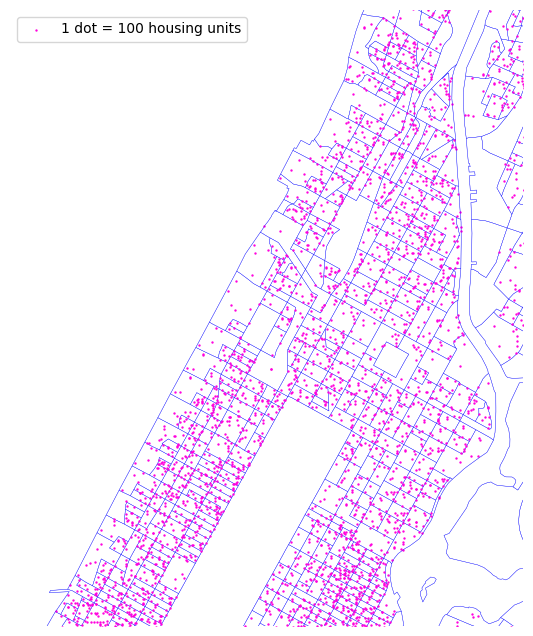

In [45]:
ax = joined.dissolve("COUNTYFP").boundary.plot(
    edgecolor="#0000ff",
    linewidth=0.35,
    alpha=0.5,
    figsize=(8, 8),
)
joined.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#0000ff",
    linewidth=0.20,
)
dots.plot(
    ax=ax,
    markersize=0.5,
    color="#ff00dd",
    label="1 dot = 100 housing units",
)
# set the legend at the axis level
ax.legend(loc="upper left")
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()

In [46]:
dots.to_file("data/processed/nyc_housing_units_dots.fgb")

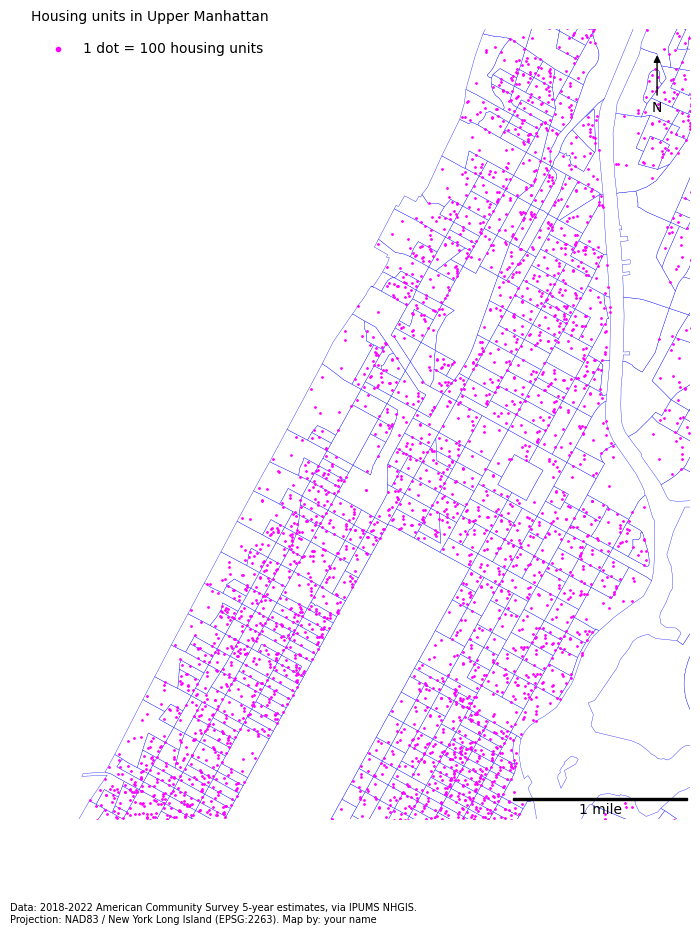

In [60]:
#Composing the map

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

# set the font type to TrueType so that it is editable in Illustrator.
# The default is Type 3, which sets all type objects as a bitmap
plt.rcParams["pdf.fonttype"] = 42

# page size in inches: swap the numbers for a landscape page
fig, ax = plt.subplots(figsize=(8.5, 11))

joined.plot(ax=ax, facecolor="white", edgecolor="#0000ff", linewidth=0.25)
dots.plot(ax=ax, markersize=1, color="#ff00ff", label="1 dot = 100 housing units")
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()

# title and legend
ax.set_title("Housing units in Upper Manhattan", loc="left", fontsize=10)
ax.legend(loc="upper left", frameon=False, markerscale=3)

# scale bar: the units of EPSG:2263 are feet, so 5280 units is 1 mile
scale_bar = AnchoredSizeBar(
    ax.transData, 5280, "1 mile", loc="lower right", frameon=False, size_vertical=40
)
ax.add_artist(scale_bar)

# north arrow
ax.annotate(
    "N",
    xy=(0.95, 0.97),
    xytext=(0.95, 0.90),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=10,
    arrowprops={"arrowstyle": "-|>", "color": "black"},
)

# data sources, projection, and cartographer
fig.text(
    0.1,
    0.06,
    "Data: 2018-2022 American Community Survey 5-year estimates, via IPUMS NHGIS.\n"
    "Projection: NAD83 / New York Long Island (EPSG:2263). Map by: your name",
    fontsize=7,
    va="top",
)

fig.savefig("tutorial02_map.pdf", bbox_inches="tight")